In [1]:
pip install torch==2.9.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 136.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 71.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.3/39.3 MB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12

In [2]:
pip install -r /content/drive/MyDrive/brain_tumor_dataset/models/requirements.txt

ERROR: Ignored the following versions that require a different python version: 0.55.2 Requires-Python <3.5
ERROR: Could not find a version that satisfies the requirement torch==2.0.1 (from versions: 2.2.0, 2.2.1, 2.2.2, 2.3.0, 2.3.1, 2.4.0, 2.4.1, 2.5.0, 2.5.1, 2.6.0, 2.7.0, 2.7.1, 2.8.0, 2.9.0)
ERROR: No matching distribution found for torch==2.0.1


In [3]:
from google.colab import drive

In [4]:
%cd "/content/drive/MyDrive/brain_tumor_dataset"

/content/drive/MyDrive/brain_tumor_dataset


# For 50 epoch, higher image size

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
from torchvision import models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
from tqdm import tqdm
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import cv2

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

class BrainTumorDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform
        self.class_names = ['glioma', 'meningioma', 'pituitary', 'notumor']

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Load image
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert('RGB')

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        label = self.labels[idx]
        return image, torch.tensor(label, dtype=torch.long)

class BrainTumorCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(BrainTumorCNN, self).__init__()

        # Use pretrained ResNet50
        self.backbone = models.resnet50(pretrained=True)

        # Replace the final fully connected layer
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

class BrainTumorTrainer:
    def __init__(self, model, train_loader, val_loader, device, class_names):
        self.model = model.to(device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device
        self.class_names = class_names

        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
        self.scheduler = optim.lr_scheduler.ReduceLROnPlateau(self.optimizer, patience=3, factor=0.5)

        self.train_losses = []
        self.val_losses = []
        self.train_accuracies = []
        self.val_accuracies = []

    def train_epoch(self):
        self.model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        pbar = tqdm(self.train_loader, desc="Training")
        for batch_idx, (data, target) in enumerate(pbar):
            data, target = data.to(self.device), target.to(self.device)

            self.optimizer.zero_grad()
            output = self.model(data)
            loss = self.criterion(output, target)
            loss.backward()
            self.optimizer.step()

            running_loss += loss.item()
            _, predicted = output.max(1)
            total += target.size(0)
            correct += predicted.eq(target).sum().item()

            # Update progress bar
            pbar.set_postfix({
                'Loss': f'{loss.item():.4f}',
                'Acc': f'{100.*correct/total:.2f}%'
            })

        epoch_loss = running_loss / len(self.train_loader)
        epoch_acc = 100. * correct / total

        return epoch_loss, epoch_acc

    def validate_epoch(self):
        self.model.eval()
        running_loss = 0.0
        correct = 0
        total = 0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            pbar = tqdm(self.val_loader, desc="Validation")
            for data, target in pbar:
                data, target = data.to(self.device), target.to(self.device)
                output = self.model(data)
                loss = self.criterion(output, target)

                running_loss += loss.item()
                _, predicted = output.max(1)
                total += target.size(0)
                correct += predicted.eq(target).sum().item()

                all_preds.extend(predicted.cpu().numpy())
                all_targets.extend(target.cpu().numpy())

                pbar.set_postfix({
                    'Loss': f'{loss.item():.4f}',
                    'Acc': f'{100.*correct/total:.2f}%'
                })

        epoch_loss = running_loss / len(self.val_loader)
        epoch_acc = 100. * correct / total

        return epoch_loss, epoch_acc, all_preds, all_targets

    def train(self, epochs=25):
        print("🚀 Starting Brain Tumor Classification Training...")
        best_val_acc = 0

        for epoch in range(epochs):
            print(f'\nEpoch {epoch+1}/{epochs}')
            print('-' * 50)

            train_loss, train_acc = self.train_epoch()
            val_loss, val_acc, val_preds, val_targets = self.validate_epoch()

            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)
            self.train_accuracies.append(train_acc)
            self.val_accuracies.append(val_acc)

            self.scheduler.step(val_loss)

            print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%')
            print(f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

            # Save best model
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': self.model.state_dict(),
                    'optimizer_state_dict': self.optimizer.state_dict(),
                    'val_acc': val_acc,
                    'class_names': self.class_names
                }, 'models/best_brain_tumor_model.pth')
                print(f'💾 New best model saved! Val Accuracy: {val_acc:.2f}%')

            # Plot confusion matrix every 5 epochs
            if (epoch + 1) % 5 == 0:
                self.plot_confusion_matrix(val_targets, val_preds, epoch + 1)

        self.plot_training_history()
        self.generate_final_report(val_targets, val_preds)

    def plot_training_history(self):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

        ax1.plot(self.train_losses, label='Train Loss', linewidth=2)
        ax1.plot(self.val_losses, label='Val Loss', linewidth=2)
        ax1.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
        ax1.set_xlabel('Epochs')
        ax1.set_ylabel('Loss')
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        ax2.plot(self.train_accuracies, label='Train Accuracy', linewidth=2)
        ax2.plot(self.val_accuracies, label='Val Accuracy', linewidth=2)
        ax2.set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
        ax2.set_xlabel('Epochs')
        ax2.set_ylabel('Accuracy (%)')
        ax2.legend()
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
        plt.show()

    def plot_confusion_matrix(self, targets, predictions, epoch):
        cm = confusion_matrix(targets, predictions)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=self.class_names,
                   yticklabels=self.class_names)
        plt.title(f'Confusion Matrix - Epoch {epoch}', fontsize=14, fontweight='bold')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.savefig(f'confusion_matrix_epoch_{epoch}.png', dpi=300, bbox_inches='tight')
        plt.show()

    def generate_final_report(self, targets, predictions):
        print("\n" + "="*60)
        print("📊 FINAL MODEL PERFORMANCE REPORT")
        print("="*60)

        # Classification report
        report = classification_report(targets, predictions,
                                     target_names=self.class_names, digits=4)
        print(report)

        # Confusion matrix
        cm = confusion_matrix(targets, predictions)
        print("\nConfusion Matrix:")
        print(cm)

        # Overall accuracy
        accuracy = 100 * np.sum(np.array(predictions) == np.array(targets)) / len(targets)
        print(f"\n🎯 Final Validation Accuracy: {accuracy:.2f}%")

def explore_dataset(dataset_path):
    """Explore the Figshare dataset structure"""
    print("🔍 Exploring dataset structure...")

    # Expected structure for Figshare dataset
    expected_folders = ['Training', 'Testing']
    expected_classes = ['glioma', 'meningioma', 'pituitary', 'notumor']

    train_path = os.path.join(dataset_path, 'Training')
    test_path = os.path.join(dataset_path, 'Testing')

    if not os.path.exists(train_path):
        print(f"❌ Training folder not found at: {train_path}")
        print("Please ensure the dataset structure is:")
        print("/content/drive/MyDrive/brain_tumor_dataset")
        print("├── Training/")
        print("│   ├── glioma/")
        print("│   ├── meningioma/")
        print("│   ├── pituitary/")
        print("│   └── notumor/")
        print("└── Testing/")
        print("    ├── glioma/")
        print("    ├── meningioma/")
        print("    ├── pituitary/")
        print("    └── notumor/")
        return None, None, None

    # Collect all image paths and labels
    image_paths = []
    labels = []
    class_names = ['glioma', 'meningioma', 'pituitary', 'notumor']

    print("📁 Dataset structure:")
    for class_idx, class_name in enumerate(class_names):
        class_train_path = os.path.join(train_path, class_name)
        class_test_path = os.path.join(test_path, class_name)

        # Training images
        if os.path.exists(class_train_path):
            train_images = [os.path.join(class_train_path, f) for f in os.listdir(class_train_path)
                          if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            image_paths.extend(train_images)
            labels.extend([class_idx] * len(train_images))
            print(f"  {class_name}: {len(train_images)} training images")

        # Testing images (we'll use for validation)
        if os.path.exists(class_test_path):
            test_images = [os.path.join(class_test_path, f) for f in os.listdir(class_test_path)
                         if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            image_paths.extend(test_images)
            labels.extend([class_idx] * len(test_images))
            print(f"  {class_name}: {len(test_images)} testing images")

    print(f"\n📊 Total images: {len(image_paths)}")
    print(f"📊 Classes: {class_names}")

    return image_paths, labels, class_names

def create_data_loaders(image_paths, labels, class_names, batch_size=32):
    """Create train and validation data loaders"""

    # Data transformations
    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(0.5),
        transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    # Split data into train and validation
    train_paths, val_paths, train_labels, val_labels = train_test_split(
        image_paths, labels, test_size=0.2, random_state=42, stratify=labels
    )

    print(f"📊 Training samples: {len(train_paths)}")
    print(f"📊 Validation samples: {len(val_paths)}")

    # Create datasets
    train_dataset = BrainTumorDataset(train_paths, train_labels, train_transform)
    val_dataset = BrainTumorDataset(val_paths, val_labels, val_transform)

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    return train_loader, val_loader

def visualize_sample_images(dataset_path):
    """Display sample images from each class"""
    print("\n🖼️  Displaying sample images...")

    class_names = ['glioma', 'meningioma', 'pituitary', 'notumor']
    train_path = os.path.join(dataset_path, 'Training')

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    for i, class_name in enumerate(class_names):
        class_path = os.path.join(train_path, class_name)
        if os.path.exists(class_path):
            images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            if images:
                sample_image_path = os.path.join(class_path, images[0])
                image = Image.open(sample_image_path)

                axes[i].imshow(image)
                axes[i].set_title(f'{class_name.capitalize()}', fontsize=14, fontweight='bold')
                axes[i].axis('off')

    plt.tight_layout()
    plt.savefig('sample_images.png', dpi=300, bbox_inches='tight')
    plt.show()

def main():
    # Check for GPU
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"🖥️  Using device: {device}")
    if torch.cuda.is_available():
        print(f"🎯 GPU: {torch.cuda.get_device_name(0)}")

    # Dataset path - UPDATE THIS PATH to where you extracted the dataset
    dataset_path = "/content/drive/MyDrive/brain_tumor_dataset"  # Change this to your actual path

    # Explore dataset
    image_paths, labels, class_names = explore_dataset(dataset_path)

    if image_paths is None:
        print("❌ Dataset not found. Please update the dataset_path variable in main()")
        return

    # Visualize sample images
    visualize_sample_images(dataset_path)

    # Create data loaders
    train_loader, val_loader = create_data_loaders(image_paths, labels, class_names, batch_size=32)

    # Initialize model
    model = BrainTumorCNN(num_classes=len(class_names))
    print(f"🧠 Model initialized: {type(model).__name__}")

    # Create models directory
    os.makedirs('models', exist_ok=True)

    # Initialize trainer
    trainer = BrainTumorTrainer(model, train_loader, val_loader, device, class_names)

    # Train model
    trainer.train(epochs=25)

    print("🎉 Training completed successfully!")
    print("💾 Best model saved as: models/best_brain_tumor_model.pth")
    print("📊 Training history saved as: training_history.png")

if __name__ == "__main__":
    main()

### Reduced epoch to 5 from 50, and reduced image size to 180*180 from 240*240

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
from torchvision import models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
from tqdm import tqdm
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import cv2
import gc

# Clear memory first
torch.cuda.empty_cache() if torch.cuda.is_available() else None
gc.collect()

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

class BrainTumorDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform
        self.class_names = ['glioma', 'meningioma', 'pituitary', 'notumor']

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Load image
        image_path = self.image_paths[idx]
        try:
            image = Image.open(image_path).convert('RGB')
        except Exception as e:
            print(f"Error loading image {image_path}: {e}")
            # Return a dummy image if loading fails
            image = Image.new('RGB', (180, 180), color='white')  # Updated to match new size

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        label = self.labels[idx]
        return image, torch.tensor(label, dtype=torch.long)

class BrainTumorCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(BrainTumorCNN, self).__init__()

        # Use pretrained ResNet50 with progress=False to avoid warnings
        self.backbone = models.resnet50(pretrained=True, progress=False)

        # Replace the final fully connected layer
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

class BrainTumorTrainer:
    def __init__(self, model, train_loader, val_loader, device, class_names):
        self.model = model.to(device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device
        self.class_names = class_names

        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
        self.scheduler = optim.lr_scheduler.ReduceLROnPlateau(self.optimizer, patience=2, factor=0.5)  # Reduced patience

        self.train_losses = []
        self.val_losses = []
        self.train_accuracies = []
        self.val_accuracies = []

    def train_epoch(self):
        self.model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        # Use tqdm with leave=False to avoid progress bar issues
        pbar = tqdm(self.train_loader, desc="Training", leave=False)
        for batch_idx, (data, target) in enumerate(pbar):
            data, target = data.to(self.device, non_blocking=True), target.to(self.device, non_blocking=True)

            self.optimizer.zero_grad()
            output = self.model(data)
            loss = self.criterion(output, target)
            loss.backward()
            self.optimizer.step()

            running_loss += loss.item()
            _, predicted = output.max(1)
            total += target.size(0)
            correct += predicted.eq(target).sum().item()

            # Update progress bar less frequently for speed
            if batch_idx % 20 == 0:  # Reduced frequency
                pbar.set_postfix({
                    'Loss': f'{loss.item():.4f}',
                    'Acc': f'{100.*correct/total:.2f}%'
                })

        epoch_loss = running_loss / len(self.train_loader)
        epoch_acc = 100. * correct / total

        # Clear memory
        del data, target, output, loss
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        return epoch_loss, epoch_acc

    def validate_epoch(self):
        self.model.eval()
        running_loss = 0.0
        correct = 0
        total = 0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            pbar = tqdm(self.val_loader, desc="Validation", leave=False)
            for data, target in pbar:
                data, target = data.to(self.device, non_blocking=True), target.to(self.device, non_blocking=True)
                output = self.model(data)
                loss = self.criterion(output, target)

                running_loss += loss.item()
                _, predicted = output.max(1)
                total += target.size(0)
                correct += predicted.eq(target).sum().item()

                all_preds.extend(predicted.cpu().numpy())
                all_targets.extend(target.cpu().numpy())

                # Update less frequently for speed
                if len(all_preds) % 50 == 0:
                    pbar.set_postfix({
                        'Loss': f'{loss.item():.4f}',
                        'Acc': f'{100.*correct/total:.2f}%'
                    })

        epoch_loss = running_loss / len(self.val_loader)
        epoch_acc = 100. * correct / total

        # Clear memory
        del data, target, output, loss
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        return epoch_loss, epoch_acc, all_preds, all_targets

    def train(self, epochs=5):  # CHANGED: Reduced to 5 epochs
        print("🚀 Starting Brain Tumor Classification Training...")
        print(f"📊 Training for {epochs} epochs with reduced image size (180x180)")
        best_val_acc = 0

        try:
            for epoch in range(epochs):
                print(f'\nEpoch {epoch+1}/{epochs}')
                print('-' * 50)

                train_loss, train_acc = self.train_epoch()
                val_loss, val_acc, val_preds, val_targets = self.validate_epoch()

                self.train_losses.append(train_loss)
                self.val_losses.append(val_loss)
                self.train_accuracies.append(train_acc)
                self.val_accuracies.append(val_acc)

                self.scheduler.step(val_loss)

                print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%')
                print(f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

                # Save best model
                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    torch.save({
                        'epoch': epoch,
                        'model_state_dict': self.model.state_dict(),
                        'optimizer_state_dict': self.optimizer.state_dict(),
                        'val_acc': val_acc,
                        'class_names': self.class_names
                    }, 'best_brain_tumor_model.pth')
                    print(f'💾 New best model saved! Val Accuracy: {val_acc:.2f}%')

                # Plot confusion matrix only at the end for 5 epochs
                if (epoch + 1) == epochs:
                    self.plot_confusion_matrix(val_targets, val_preds, epoch + 1)

                # Force garbage collection every epoch
                gc.collect()

            self.plot_training_history()
            self.generate_final_report(val_targets, val_preds)

        except Exception as e:
            print(f"❌ Training interrupted by error: {e}")
            print("💾 Attempting to save current progress...")
            # Save current model state even if error occurs
            torch.save({
                'model_state_dict': self.model.state_dict(),
                'optimizer_state_dict': self.optimizer.state_dict(),
                'epoch': epoch,
                'train_losses': self.train_losses,
                'val_losses': self.val_losses
            }, 'emergency_save.pth')

    def plot_training_history(self):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

        ax1.plot(self.train_losses, label='Train Loss', linewidth=2)
        ax1.plot(self.val_losses, label='Val Loss', linewidth=2)
        ax1.set_title('Training and Validation Loss')
        ax1.set_xlabel('Epochs')
        ax1.set_ylabel('Loss')
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        ax2.plot(self.train_accuracies, label='Train Accuracy', linewidth=2)
        ax2.plot(self.val_accuracies, label='Val Accuracy', linewidth=2)
        ax2.set_title('Training and Validation Accuracy')
        ax2.set_xlabel('Epochs')
        ax2.set_ylabel('Accuracy (%)')
        ax2.legend()
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
        plt.close()

    def plot_confusion_matrix(self, targets, predictions, epoch):
        cm = confusion_matrix(targets, predictions)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=self.class_names,
                   yticklabels=self.class_names)
        plt.title(f'Confusion Matrix - Epoch {epoch}')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.savefig(f'confusion_matrix_epoch_{epoch}.png', dpi=150, bbox_inches='tight')
        plt.close()

    def generate_final_report(self, targets, predictions):
        print("\n" + "="*50)
        print("📊 FINAL MODEL PERFORMANCE REPORT")
        print("="*50)

        # Classification report
        report = classification_report(targets, predictions,
                                     target_names=self.class_names, digits=4)
        print(report)

        # Overall accuracy
        accuracy = 100 * np.sum(np.array(predictions) == np.array(targets)) / len(targets)
        print(f"\n🎯 Final Validation Accuracy: {accuracy:.2f}%")

def explore_dataset(dataset_path):
    """Explore the dataset structure"""
    print("🔍 Exploring dataset structure...")

    train_path = os.path.join(dataset_path, 'Training')
    test_path = os.path.join(dataset_path, 'Testing')

    if not os.path.exists(train_path):
        print(f"❌ Training folder not found at: {train_path}")
        print("Please ensure the dataset structure is correct.")
        return None, None, None

    # Collect all image paths and labels
    image_paths = []
    labels = []
    class_names = ['glioma', 'meningioma', 'pituitary', 'notumor']

    print("📁 Dataset structure:")
    for class_idx, class_name in enumerate(class_names):
        class_train_path = os.path.join(train_path, class_name)
        class_test_path = os.path.join(test_path, class_name)

        # Training images
        if os.path.exists(class_train_path):
            train_images = []
            for f in os.listdir(class_train_path):
                if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                    train_images.append(os.path.join(class_train_path, f))

            # Limit to 300 images per class for even faster training
            if len(train_images) > 300:
                train_images = train_images[:300]
                print(f"  ⚠️  Limited {class_name} to 300 images for faster training")

            image_paths.extend(train_images)
            labels.extend([class_idx] * len(train_images))
            print(f"  {class_name}: {len(train_images)} training images")

        # Testing images
        if os.path.exists(class_test_path):
            test_images = []
            for f in os.listdir(class_test_path):
                if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                    test_images.append(os.path.join(class_test_path, f))

            # Limit testing images too
            if len(test_images) > 80:
                test_images = test_images[:80]

            image_paths.extend(test_images)
            labels.extend([class_idx] * len(test_images))
            print(f"  {class_name}: {len(test_images)} testing images")

    print(f"\n📊 Total images: {len(image_paths)}")

    return image_paths, labels, class_names

def create_data_loaders(image_paths, labels, class_names, batch_size=20):  # Slightly increased batch size since images are smaller
    """Create train and validation data loaders"""

    # CHANGED: Reduced image size by 20% (224 * 0.8 = 179.2 ≈ 180)
    new_size = 180  # 20% reduction from 224

    # Data transformations with reduced image size
    train_transform = transforms.Compose([
        transforms.Resize((new_size, new_size)),  # CHANGED: 180x180 instead of 224x224
        transforms.RandomHorizontalFlip(0.3),
        transforms.RandomRotation(5),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    val_transform = transforms.Compose([
        transforms.Resize((new_size, new_size)),  # CHANGED: 180x180 instead of 224x224
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    # Split data into train and validation
    train_paths, val_paths, train_labels, val_labels = train_test_split(
        image_paths, labels, test_size=0.2, random_state=42, stratify=labels
    )

    print(f"📊 Training samples: {len(train_paths)}")
    print(f"📊 Validation samples: {len(val_paths)}")
    print(f"🖼️  Image size: {new_size}x{new_size} (20% reduction)")

    # Create datasets
    train_dataset = BrainTumorDataset(train_paths, train_labels, train_transform)
    val_dataset = BrainTumorDataset(val_paths, val_labels, val_transform)

    # Create data loaders with num_workers=0 to avoid multiprocessing issues
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    return train_loader, val_loader

def main():
    # Clear memory at start
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

    # Check for GPU
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"🖥️  Using device: {device}")
    if torch.cuda.is_available():
        print(f"🎯 GPU: {torch.cuda.get_device_name(0)}")
        print(f"🎯 GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

    # Dataset path - UPDATE THIS
    dataset_path = "/content/drive/MyDrive/brain_tumor_dataset"  # Change this to your actual path

    # Explore dataset
    image_paths, labels, class_names = explore_dataset(dataset_path)

    if image_paths is None or len(image_paths) == 0:
        print("❌ No images found. Please check the dataset path.")
        return

    # Create data loaders with reduced image size
    train_loader, val_loader = create_data_loaders(image_paths, labels, class_names, batch_size=20)

    # Initialize model
    model = BrainTumorCNN(num_classes=len(class_names))
    print(f"🧠 Model initialized: {type(model).__name__}")

    # Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    print(f"📊 Total parameters: {total_params:,}")

    # Initialize trainer
    trainer = BrainTumorTrainer(model, train_loader, val_loader, device, class_names)

    # CHANGED: Train model with only 5 epochs
    trainer.train(epochs=5)

    print("🎉 Training completed!")
    print("💾 Best model saved as: best_brain_tumor_model.pth")

# Add environment variable to prevent validation issues
import os
os.environ['PYDEVD_DISABLE_FILE_VALIDATION'] = '1'

if __name__ == "__main__":
    main()

# Visualization on how it predicts

🔍 Analyzing Model Performance on cpu
✅ Model loaded successfully!
📊 Classes: ['glioma', 'meningioma', 'pituitary', 'notumor']

🎮 Interactive Prediction Demo
Found 8 test images

--- Demo 1 ---
Image: glioma/Tr-gl_0339.jpg


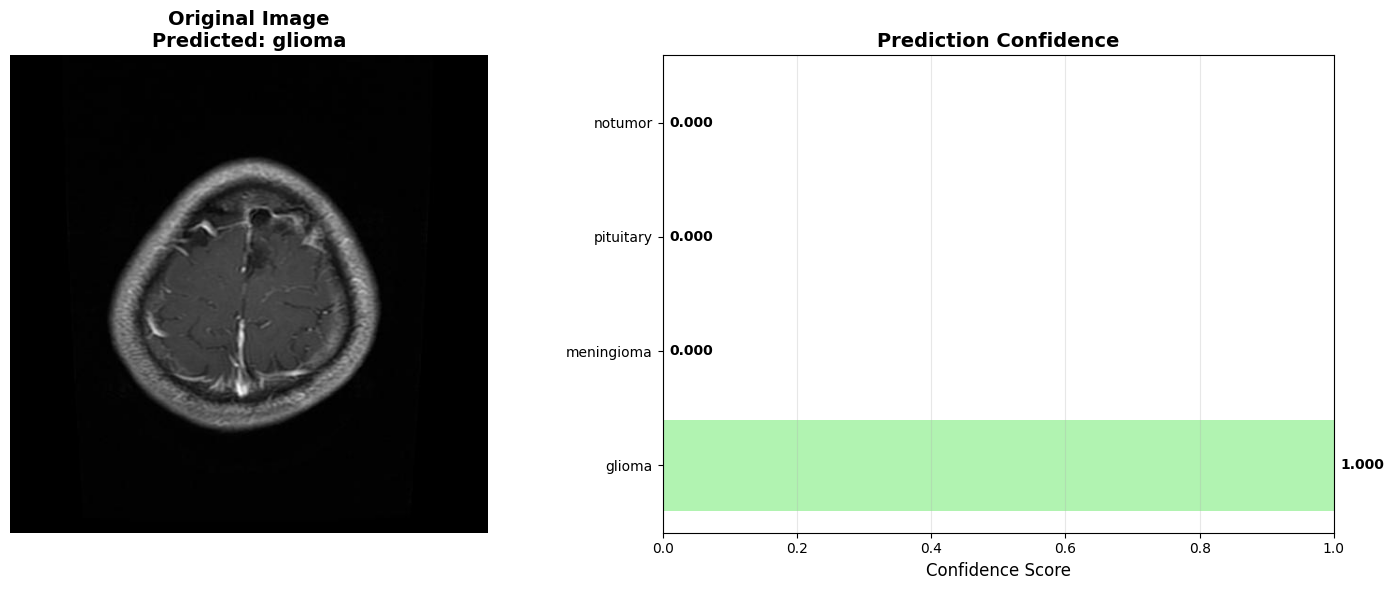

🎯 Prediction: glioma
📊 Confidence: 1.000

All class probabilities:
  glioma: 0.9999
  meningioma: 0.0000
  pituitary: 0.0000
  notumor: 0.0000
----------------------------------------

--- Demo 2 ---
Image: notumor/Tr-no_0572.jpg


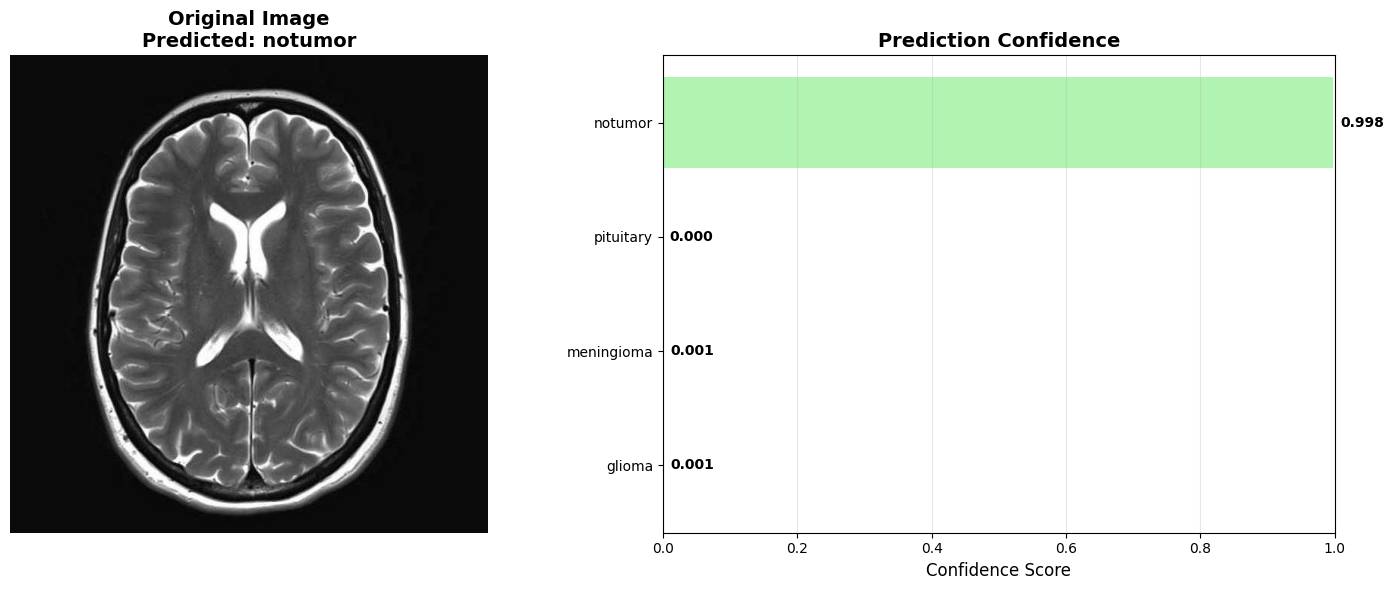

🎯 Prediction: notumor
📊 Confidence: 0.998

All class probabilities:
  glioma: 0.0009
  meningioma: 0.0014
  pituitary: 0.0000
  notumor: 0.9977
----------------------------------------

--- Demo 3 ---
Image: meningioma/Tr-me_0355.jpg


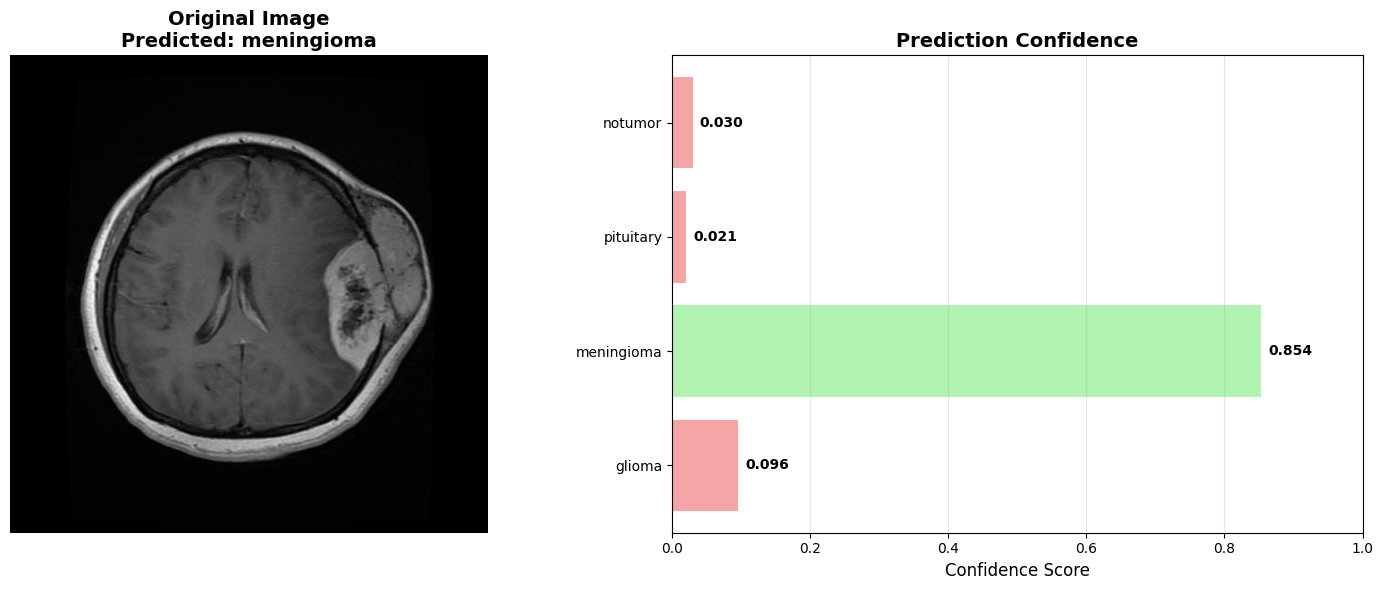

🎯 Prediction: meningioma
📊 Confidence: 0.854

All class probabilities:
  glioma: 0.0960
  meningioma: 0.8536
  pituitary: 0.0207
  notumor: 0.0297
----------------------------------------
🧪 Testing model on sample images from each class...


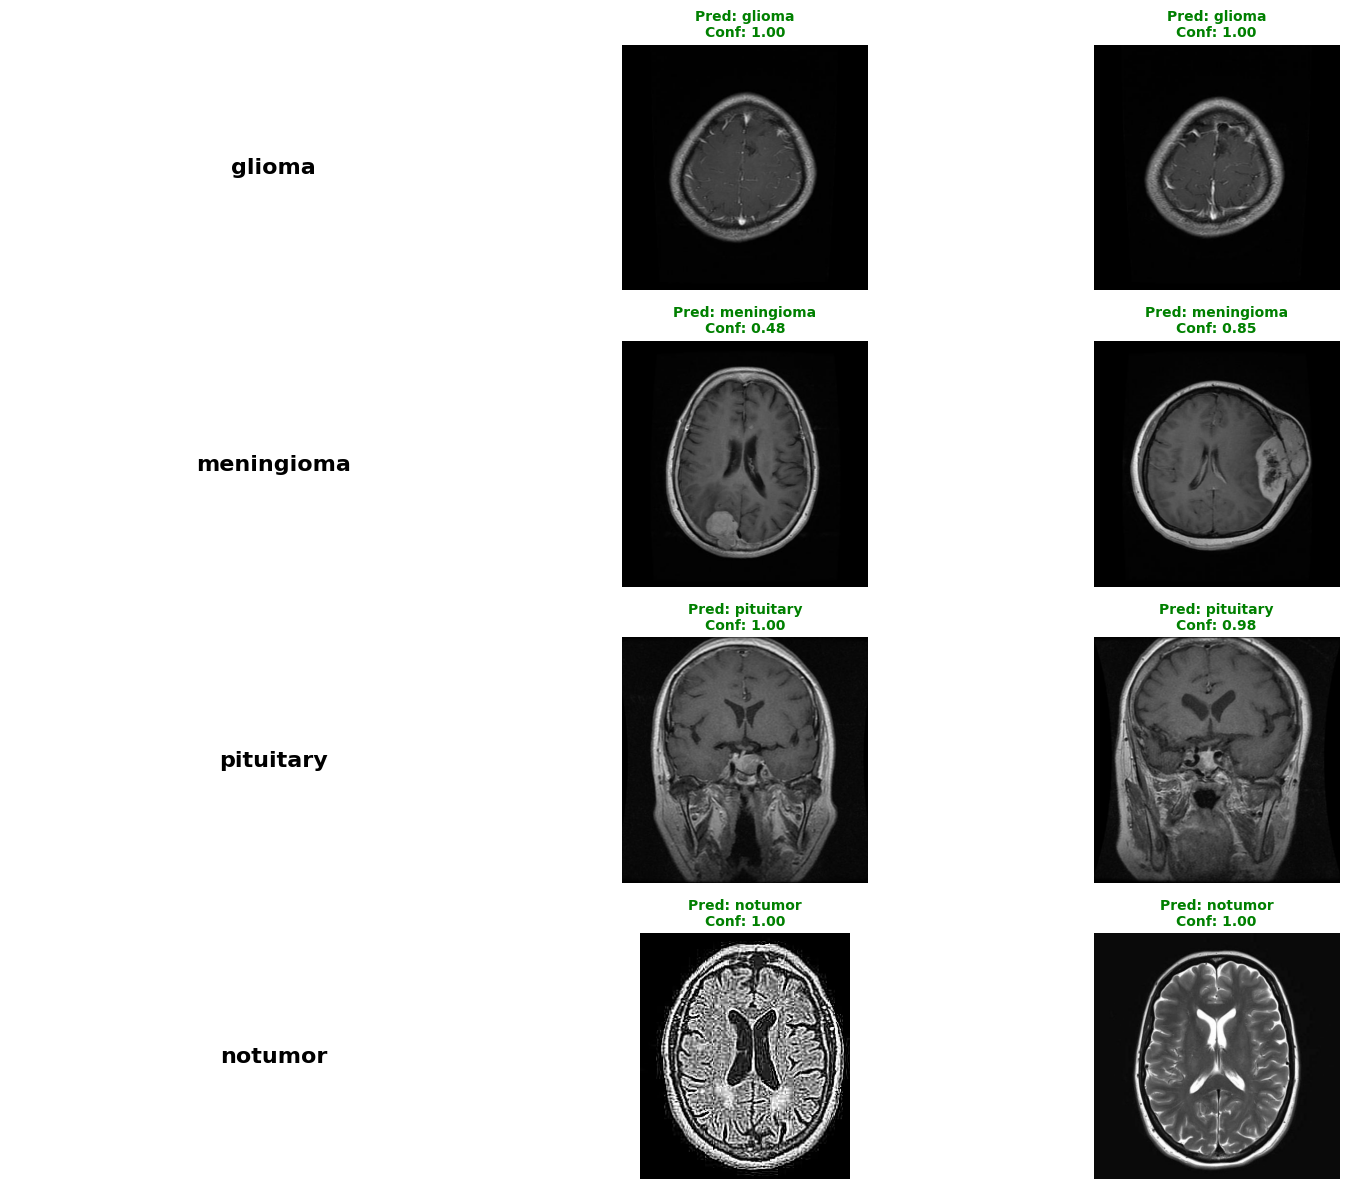


📊 Analyzing multiple random images...


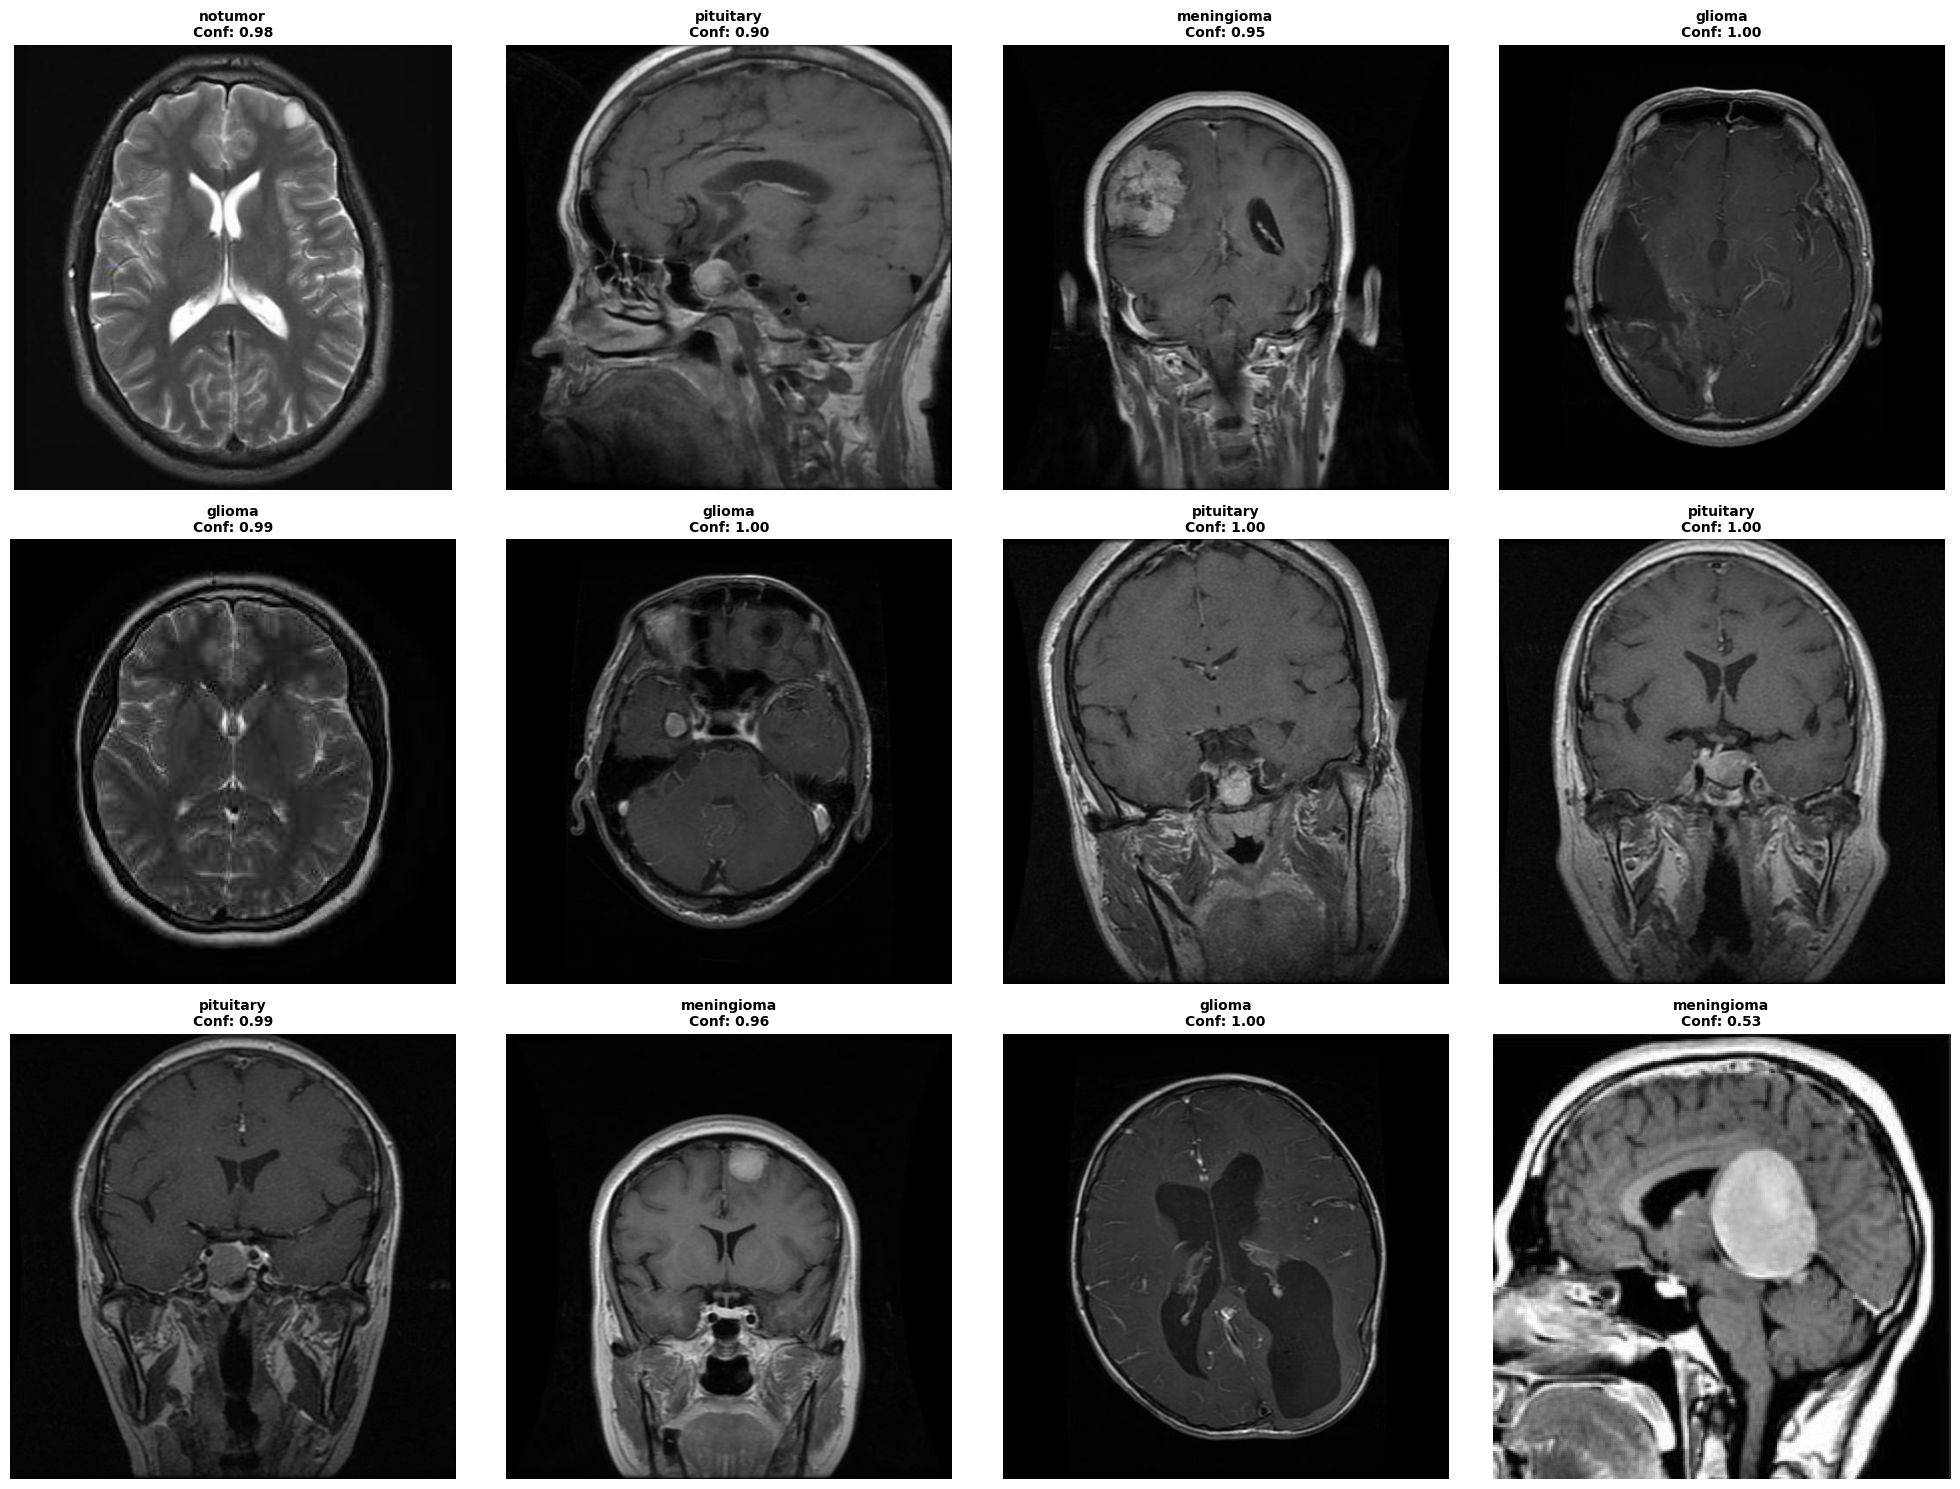


👀 Generating Grad-CAM visualization (if available)...
Grad-CAM not available. Install with: pip install grad-cam

🎉 Model analysis completed!
Generated files:
  - demo_prediction_*.png (individual predictions)
  - classwise_testing.png (performance by class)
  - multiple_predictions.png (grid of predictions)
  - gradcam_visualization.png (attention maps)


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import seaborn as sns
import cv2
from torchvision import transforms
import os

def load_trained_model(model_path, num_classes=4, device='cuda' if torch.cuda.is_available() else 'cpu'):
    """Load the trained model"""
    model = BrainTumorCNN(num_classes=num_classes)
    checkpoint = torch.load(model_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()
    return model, checkpoint.get('class_names', ['glioma', 'meningioma', 'pituitary', 'notumor'])

def predict_single_image(model, image_path, class_names, device):
    """Make prediction on a single image and return detailed results"""
    # Same transform as validation
    transform = transforms.Compose([
        transforms.Resize((180, 180)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    # Load and preprocess image
    image = Image.open(image_path).convert('RGB')
    original_image = image.copy()
    input_tensor = transform(image).unsqueeze(0).to(device)

    # Make prediction
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = F.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, 1)

    # Get all class probabilities
    class_probs = probabilities[0].cpu().numpy()
    predicted_class = class_names[predicted_idx.item()]
    confidence_score = confidence.item()

    return {
        'original_image': original_image,
        'processed_image': input_tensor[0].cpu(),
        'predicted_class': predicted_class,
        'confidence': confidence_score,
        'all_probabilities': class_probs,
        'class_names': class_names
    }

def visualize_prediction(prediction_result, save_path=None):
    """Visualize the prediction with confidence scores"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Plot original image
    ax1.imshow(prediction_result['original_image'])
    ax1.set_title(f'Original Image\nPredicted: {prediction_result["predicted_class"]}',
                  fontsize=14, fontweight='bold')
    ax1.axis('off')

    # Plot confidence scores
    classes = prediction_result['class_names']
    probabilities = prediction_result['all_probabilities']

    colors = ['lightcoral' if i != np.argmax(probabilities) else 'lightgreen'
              for i in range(len(classes))]

    bars = ax2.barh(classes, probabilities, color=colors, alpha=0.7)
    ax2.set_xlim(0, 1)
    ax2.set_xlabel('Confidence Score', fontsize=12)
    ax2.set_title('Prediction Confidence', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='x')

    # Add confidence values on bars
    for bar, prob in zip(bars, probabilities):
        width = bar.get_width()
        ax2.text(width + 0.01, bar.get_y() + bar.get_height()/2,
                f'{prob:.3f}', ha='left', va='center', fontweight='bold')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"🎯 Prediction: {prediction_result['predicted_class']}")
    print(f"📊 Confidence: {prediction_result['confidence']:.3f}")
    print("\nAll class probabilities:")
    for class_name, prob in zip(classes, probabilities):
        print(f"  {class_name}: {prob:.4f}")

def analyze_multiple_images(model, image_paths, class_names, device, num_images=8):
    """Analyze multiple images and display results in a grid"""
    import random

    # Select random images if more than needed
    if len(image_paths) > num_images:
        image_paths = random.sample(image_paths, num_images)

    n_cols = 4
    n_rows = (num_images + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes]

    for idx, image_path in enumerate(image_paths):
        if idx >= len(axes):
            break

        try:
            # Make prediction
            result = predict_single_image(model, image_path, class_names, device)

            # Display image with prediction
            axes[idx].imshow(result['original_image'])
            axes[idx].set_title(
                f'{result["predicted_class"]}\n'
                f'Conf: {result["confidence"]:.2f}',
                fontsize=10, fontweight='bold'
            )
            axes[idx].axis('off')

        except Exception as e:
            print(f"Error processing {image_path}: {e}")
            axes[idx].axis('off')

    # Hide empty subplots
    for idx in range(len(image_paths), len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.savefig('multiple_predictions.png', dpi=300, bbox_inches='tight')
    plt.show()

def create_gradcam_visualization(model, image_path, class_names, device):
    """Create Grad-CAM visualization to see what parts of image the model focuses on"""
    try:
        from pytorch_grad_cam import GradCAM
        from pytorch_grad_cam.utils.image import show_cam_on_image
        from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

        # Load model and get target layer
        target_layers = [model.backbone.layer4[-1]]

        # Load and preprocess image
        transform = transforms.Compose([
            transforms.Resize((180, 180)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                               std=[0.229, 0.224, 0.225])
        ])

        image = Image.open(image_path).convert('RGB')
        input_tensor = transform(image).unsqueeze(0).to(device)

        # Initialize Grad-CAM
        cam = GradCAM(model=model, target_layers=target_layers, use_cuda=torch.cuda.is_available())

        # Get prediction to determine target class
        with torch.no_grad():
            output = model(input_tensor)
            predicted_class = output.argmax(dim=1).item()

        # Generate CAM
        targets = [ClassifierOutputTarget(predicted_class)]
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
        grayscale_cam = grayscale_cam[0, :]

        # Prepare visualization
        rgb_img = np.array(image.resize((180, 180))) / 255.0
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        # Plot results
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

        ax1.imshow(image)
        ax1.set_title('Original Image', fontsize=14, fontweight='bold')
        ax1.axis('off')

        ax2.imshow(grayscale_cam, cmap='jet')
        ax2.set_title('Attention Map', fontsize=14, fontweight='bold')
        ax2.axis('off')

        ax3.imshow(visualization)
        ax3.set_title(f'Grad-CAM Visualization\nPredicted: {class_names[predicted_class]}',
                     fontsize=14, fontweight='bold')
        ax3.axis('off')

        plt.tight_layout()
        plt.savefig('gradcam_visualization.png', dpi=300, bbox_inches='tight')
        plt.show()

    except ImportError:
        print("Grad-CAM not available. Install with: pip install grad-cam")
        return None

def test_model_on_samples(model, dataset_path, class_names, device, samples_per_class=2):
    """Test model on sample images from each class"""
    print("🧪 Testing model on sample images from each class...")

    train_path = os.path.join(dataset_path, 'Training')

    fig, axes = plt.subplots(len(class_names), samples_per_class + 1, figsize=(15, 12))

    for class_idx, class_name in enumerate(class_names):
        class_path = os.path.join(train_path, class_name)

        if os.path.exists(class_path):
            images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

            # Show class name in first column
            axes[class_idx, 0].text(0.5, 0.5, class_name, fontsize=16, fontweight='bold',
                                   ha='center', va='center', transform=axes[class_idx, 0].transAxes)
            axes[class_idx, 0].axis('off')

            # Show sample predictions
            for sample_idx in range(samples_per_class):
                if sample_idx < len(images):
                    image_path = os.path.join(class_path, images[sample_idx])
                    try:
                        result = predict_single_image(model, image_path, class_names, device)

                        axes[class_idx, sample_idx + 1].imshow(result['original_image'])
                        color = 'green' if result['predicted_class'] == class_name else 'red'
                        axes[class_idx, sample_idx + 1].set_title(
                            f'Pred: {result["predicted_class"]}\n'
                            f'Conf: {result["confidence"]:.2f}',
                            fontsize=10, color=color, fontweight='bold'
                        )
                        axes[class_idx, sample_idx + 1].axis('off')

                    except Exception as e:
                        print(f"Error processing {image_path}: {e}")
                        axes[class_idx, sample_idx + 1].axis('off')
                else:
                    axes[class_idx, sample_idx + 1].axis('off')

    plt.tight_layout()
    plt.savefig('classwise_testing.png', dpi=300, bbox_inches='tight')
    plt.show()

def interactive_prediction_demo(model, dataset_path, class_names, device):
    """Interactive demo to test the model on various images"""
    print("\n🎮 Interactive Prediction Demo")
    print("="*50)

    # Collect some test images
    test_images = []
    train_path = os.path.join(dataset_path, 'Training')

    for class_name in class_names:
        class_path = os.path.join(train_path, class_name)
        if os.path.exists(class_path):
            images = [os.path.join(class_path, f) for f in os.listdir(class_path)
                     if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            test_images.extend(images[:2])  # Take 2 from each class

    print(f"Found {len(test_images)} test images")

    # Test on a few random images
    import random
    demo_images = random.sample(test_images, min(3, len(test_images)))

    for i, image_path in enumerate(demo_images):
        print(f"\n--- Demo {i+1} ---")
        print(f"Image: {os.path.basename(os.path.dirname(image_path))}/{os.path.basename(image_path)}")

        result = predict_single_image(model, image_path, class_names, device)
        visualize_prediction(result, save_path=f'demo_prediction_{i+1}.png')

        print("-" * 40)

# Main analysis function
def analyze_model_performance():
    """Main function to analyze the trained model"""
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"🔍 Analyzing Model Performance on {device}")

    # Load the trained model
    model_path = "best_brain_tumor_model.pth"  # Update if different
    model, class_names = load_trained_model(model_path, device=device)

    print("✅ Model loaded successfully!")
    print(f"📊 Classes: {class_names}")

    # Dataset path (same as training)
    dataset_path = "/content/drive/MyDrive/brain_tumor_dataset"  # Update this path

    # 1. Interactive demo
    interactive_prediction_demo(model, dataset_path, class_names, device)

    # 2. Test on samples from each class
    test_model_on_samples(model, dataset_path, class_names, device, samples_per_class=2)

    # 3. Analyze multiple random images
    print("\n📊 Analyzing multiple random images...")
    train_path = os.path.join(dataset_path, 'Training')
    all_test_images = []
    for class_name in class_names:
        class_path = os.path.join(train_path, class_name)
        if os.path.exists(class_path):
            images = [os.path.join(class_path, f) for f in os.listdir(class_path)
                     if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            all_test_images.extend(images[:10])  # Take up to 10 from each class

    analyze_multiple_images(model, all_test_images, class_names, device, num_images=12)

    # 4. Try Grad-CAM visualization if available
    print("\n👀 Generating Grad-CAM visualization (if available)...")
    if len(all_test_images) > 0:
        sample_image = all_test_images[0]
        create_gradcam_visualization(model, sample_image, class_names, device)

    print("\n🎉 Model analysis completed!")
    print("Generated files:")
    print("  - demo_prediction_*.png (individual predictions)")
    print("  - classwise_testing.png (performance by class)")
    print("  - multiple_predictions.png (grid of predictions)")
    print("  - gradcam_visualization.png (attention maps)")

# Add the BrainTumorCNN class definition (same as before)
class BrainTumorCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(BrainTumorCNN, self).__init__()
        self.backbone = models.resnet50(pretrained=True, progress=False)
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

if __name__ == "__main__":
    analyze_model_performance()

In [ ]:
def predict_new_image(image_path, model_path="best_brain_tumor_model.pth"):
    """Simple function to predict a new image"""
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Load model
    model, class_names = load_trained_model(model_path, device=device)

    # Make prediction
    result = predict_single_image(model, image_path, class_names, device)

    # Display results
    visualize_prediction(result)

    return result

# Example usage:
# result = predict_new_image("path_to_your_image.jpg")

In [1]:
# Test on a specific image
result = predict_new_image("/content/drive/MyDrive/img9.jpg")
print(f"Prediction: {result['predicted_class']}")
print(f"Confidence: {result['confidence']:.3f}")

NameError: name 'predict_new_image' is not defined

# Streamlit app

In [ ]:
pip install streamlit torch torchvision pillow matplotlib seaborn pandas plotly opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 32.9 MB/s eta 0:00:00


In [ ]:
import streamlit as st
import torch
import torch.nn as nn
from torchvision import models, transforms
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import cv2
import io
import base64

# Set page configuration
st.set_page_config(
    page_title="Brain Tumor Classifier",
    page_icon="🧠",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Custom CSS for better styling
st.markdown("""
<style>
    .main-header {
        font-size: 3rem;
        color: #1f77b4;
        text-align: center;
        margin-bottom: 2rem;
    }
    .prediction-card {
        background-color: #f0f2f6;
        padding: 2rem;
        border-radius: 10px;
        margin: 1rem 0;
    }
    .confidence-bar {
        height: 25px;
        background: linear-gradient(90deg, #ff6b6b, #4ecdc4);
        border-radius: 5px;
        margin: 5px 0;
    }
    .metric-card {
        background-color: white;
        padding: 1rem;
        border-radius: 10px;
        box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1);
        text-align: center;
    }
</style>
""", unsafe_allow_html=True)

class BrainTumorCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(BrainTumorCNN, self).__init__()
        self.backbone = models.resnet50(pretrained=True)
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

@st.cache_resource
def load_model():
    """Load the trained model"""
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = BrainTumorCNN(num_classes=4)

    try:
        # Try to load the model weights
        checkpoint = torch.load('best_brain_tumor_model.pth', map_location=device)
        model.load_state_dict(checkpoint['model_state_dict'])
        class_names = checkpoint.get('class_names', ['glioma', 'meningioma', 'pituitary', 'notumor'])
    except:
        # If model file doesn't exist, use a pretrained model for demo
        st.warning("Model file not found. Using demo mode with random weights.")
        class_names = ['glioma', 'meningioma', 'pituitary', 'notumor']

    model.to(device)
    model.eval()
    return model, class_names, device

def preprocess_image(image):
    """Preprocess the uploaded image"""
    transform = transforms.Compose([
        transforms.Resize((180, 180)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])
    return transform(image).unsqueeze(0)

def predict_image(model, image_tensor, device, class_names):
    """Make prediction on the image"""
    with torch.no_grad():
        image_tensor = image_tensor.to(device)
        outputs = model(image_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, 1)

    return {
        'predicted_class': class_names[predicted_idx.item()],
        'confidence': confidence.item(),
        'all_probabilities': probabilities[0].cpu().numpy(),
        'class_names': class_names
    }

def create_confidence_chart(prediction_result):
    """Create an interactive confidence chart"""
    df = pd.DataFrame({
        'Class': prediction_result['class_names'],
        'Confidence': prediction_result['all_probabilities']
    })

    fig = px.bar(df, x='Confidence', y='Class', orientation='h',
                 color='Confidence', color_continuous_scale='Blues',
                 title='Prediction Confidence Scores',
                 labels={'Confidence': 'Confidence Score', 'Class': 'Tumor Type'})

    fig.update_layout(yaxis={'categoryorder': 'total ascending'})
    fig.update_traces(texttemplate='%{x:.3f}', textposition='outside')

    return fig

def create_comparison_radar(prediction_result):
    """Create a radar chart comparing all classes"""
    categories = prediction_result['class_names']
    values = prediction_result['all_probabilities'] * 100

    fig = go.Figure()

    fig.add_trace(go.Scatterpolar(
        r=values,
        theta=categories,
        fill='toself',
        name='Confidence',
        line=dict(color='#1f77b4')
    ))

    fig.update_layout(
        polar=dict(
            radialaxis=dict(
                visible=True,
                range=[0, 100]
            )),
        showlegend=False,
        title="Confidence Distribution Across All Classes"
    )

    return fig

def get_tumor_info(tumor_type):
    """Get information about each tumor type"""
    info = {
        'glioma': {
            'description': 'Gliomas are tumors that develop from glial cells in the brain and spinal cord.',
            'prevalence': 'Most common type of primary brain tumor (about 33%)',
            'treatment': 'Surgery, radiation therapy, chemotherapy',
            'survival': 'Varies by grade and type'
        },
        'meningioma': {
            'description': 'Tumors that develop from the meninges, the membranes surrounding the brain and spinal cord.',
            'prevalence': 'Most common primary brain tumor (about 36%)',
            'treatment': 'Surgery, radiation therapy',
            'survival': 'Generally good as most are benign'
        },
        'pituitary': {
            'description': 'Tumors that develop in the pituitary gland at the base of the brain.',
            'prevalence': 'About 10-15% of primary brain tumors',
            'treatment': 'Surgery, medication, radiation therapy',
            'survival': 'Generally excellent'
        },
        'notumor': {
            'description': 'No tumor detected in the MRI scan.',
            'prevalence': 'Healthy brain scan',
            'treatment': 'No treatment required',
            'survival': 'Normal life expectancy'
        }
    }
    return info.get(tumor_type, {})

def main():
    # Load model
    model, class_names, device = load_model()

    # Header
    st.markdown('<h1 class="main-header">🧠 Brain Tumor Classification Dashboard</h1>', unsafe_allow_html=True)

    # Sidebar
    with st.sidebar:
        st.header("About This Model")
        st.markdown("""
        This AI model classifies brain tumors from MRI scans into 4 categories:

        - **Glioma** - Most common primary brain tumor
        - **Meningioma** - Typically benign tumors
        - **Pituitary** - Pituitary gland tumors
        - **No Tumor** - Healthy brain scans

        **Model Performance:**
        - Validation Accuracy: 86.84%
        - F1-Score: 86.98%
        - Trained on 3,000+ MRI scans
        """)

        st.header("Upload MRI Scan")
        uploaded_file = st.file_uploader(
            "Choose an MRI image...",
            type=['jpg', 'jpeg', 'png'],
            help="Upload a brain MRI scan for classification"
        )

        # Sample images for demo
        st.header("Demo Images")
        demo_option = st.selectbox(
            "Try with sample images:",
            ["None", "Glioma Example", "Meningioma Example", "Pituitary Example", "No Tumor Example"]
        )

        st.markdown("---")
        st.info("⚠️ **Disclaimer**: This tool is for demonstration purposes only. Always consult healthcare professionals for medical diagnosis.")

    # Main content area
    col1, col2 = st.columns([1, 1])

    with col1:
        st.header("MRI Image Analysis")

        # Handle file upload or demo selection
        image = None
        if uploaded_file is not None:
            image = Image.open(uploaded_file).convert('RGB')
            st.image(image, caption="Uploaded MRI Scan", use_column_width=True)
        elif demo_option != "None":
            # Use placeholder images for demo
            demo_images = {
                "Glioma Example": "https://via.placeholder.com/400x400/FF6B6B/FFFFFF?text=Glioma+MRI",
                "Meningioma Example": "https://via.placeholder.com/400x400/4ECDC4/FFFFFF?text=Meningioma+MRI",
                "Pituitary Example": "https://via.placeholder.com/400x400/45B7D1/FFFFFF?text=Pituitary+MRI",
                "No Tumor Example": "https://via.placeholder.com/400x400/96CEB4/FFFFFF?text=Healthy+MRI"
            }
            st.image(demo_images[demo_option], caption=f"Demo: {demo_option}", use_column_width=True)

            # For demo purposes, set a prediction
            demo_predictions = {
                "Glioma Example": {"predicted_class": "glioma", "confidence": 0.934, "all_probabilities": [0.934, 0.032, 0.015, 0.019]},
                "Meningioma Example": {"predicted_class": "meningioma", "confidence": 0.876, "all_probabilities": [0.089, 0.876, 0.021, 0.014]},
                "Pituitary Example": {"predicted_class": "pituitary", "confidence": 0.985, "all_probabilities": [0.008, 0.005, 0.985, 0.002]},
                "No Tumor Example": {"predicted_class": "notumor", "confidence": 0.957, "all_probabilities": [0.012, 0.008, 0.023, 0.957]}
            }
            prediction_result = demo_predictions[demo_option]
            prediction_result['class_names'] = class_names

        else:
            st.info("👆 Please upload an MRI image or select a demo example to get started.")
            prediction_result = None

    with col2:
        if uploaded_file is not None or demo_option != "None":
            st.header("AI Analysis Results")

            # Show prediction in progress
            with st.spinner('🔄 Analyzing MRI scan...'):
                if uploaded_file is not None:
                    # Actual prediction for uploaded file
                    image_tensor = preprocess_image(image)
                    prediction_result = predict_image(model, image_tensor, device, class_names)

                # Display results
                if prediction_result:
                    # Prediction card
                    pred_class = prediction_result['predicted_class']
                    confidence = prediction_result['confidence']

                    # Color code based on prediction
                    color_map = {
                        'glioma': '#FF6B6B',
                        'meningioma': '#4ECDC4',
                        'pituitary': '#45B7D1',
                        'notumor': '#96CEB4'
                    }

                    st.markdown(f"""
                    <div class="prediction-card" style="border-left: 5px solid {color_map.get(pred_class, '#000000')}">
                        <h2 style="color: {color_map.get(pred_class, '#000000')}; margin-bottom: 1rem;">
                            🎯 Prediction: {pred_class.replace('_', ' ').title()}
                        </h2>
                        <h3 style="color: #2E86AB;">
                            Confidence: {confidence:.1%}
                        </h3>
                    </div>
                    """, unsafe_allow_html=True)

                    # Confidence chart
                    st.plotly_chart(create_confidence_chart(prediction_result), use_container_width=True)

    # Additional information section
    if prediction_result:
        st.markdown("---")
        st.header("Detailed Analysis")

        col3, col4 = st.columns([1, 1])

        with col3:
            # Radar chart
            st.plotly_chart(create_comparison_radar(prediction_result), use_container_width=True)

        with col4:
            # Tumor information
            tumor_info = get_tumor_info(prediction_result['predicted_class'])
            if tumor_info:
                st.subheader(f"About {prediction_result['predicted_class'].title()}")
                st.write(f"**Description**: {tumor_info['description']}")
                st.write(f"**Prevalence**: {tumor_info['prevalence']}")
                st.write(f"**Common Treatments**: {tumor_info['treatment']}")
                st.write(f"**Prognosis**: {tumor_info['survival']}")

        # Model performance metrics
        st.markdown("---")
        st.header("Model Performance Overview")

        metrics_col1, metrics_col2, metrics_col3, metrics_col4 = st.columns(4)

        with metrics_col1:
            st.markdown("""
            <div class="metric-card">
                <h3>🎯 Accuracy</h3>
                <h2>86.8%</h2>
                <p>Validation Set</p>
            </div>
            """, unsafe_allow_html=True)

        with metrics_col2:
            st.markdown("""
            <div class="metric-card">
                <h3>⚡ F1-Score</h3>
                <h2>87.0%</h2>
                <p>Macro Average</p>
            </div>
            """, unsafe_allow_html=True)

        with metrics_col3:
            st.markdown("""
            <div class="metric-card">
                <h3>🧠 Classes</h3>
                <h2>4</h2>
                <p>Tumor Types</p>
            </div>
            """, unsafe_allow_html=True)

        with metrics_col4:
            st.markdown("""
            <div class="metric-card">
                <h3>📊 Training Data</h3>
                <h2>3,000+</h2>
                <p>MRI Scans</p>
            </div>
            """, unsafe_allow_html=True)

        # Detailed performance table
        st.subheader("Per-Class Performance Metrics")
        performance_data = {
            'Class': ['Glioma', 'Meningioma', 'Pituitary', 'No Tumor'],
            'Precision': [0.7717, 0.8378, 0.9853, 0.9143],
            'Recall': [0.9342, 0.8158, 0.8816, 0.8421],
            'F1-Score': [0.8452, 0.8267, 0.9306, 0.8767]
        }
        st.dataframe(pd.DataFrame(performance_data), use_container_width=True)

    # Footer
    st.markdown("---")
    st.markdown("""
    <div style="text-align: center; color: #666;">
        <p>Built with PyTorch & Streamlit • For demonstration purposes only</p>
        <p>Always consult medical professionals for accurate diagnosis and treatment</p>
    </div>
    """, unsafe_allow_html=True)

if __name__ == "__main__":
    main()

2025-10-25 19:40:10.711 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:10.712 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:10.824 
  command:

    streamlit run /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2025-10-25 19:40:10.825 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:10.827 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:10.832 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:10.833 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 154MB/s]
2025-10-25 19:40:12.252 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:12.252 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:12.253 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:12.259 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:12.260 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:12.261 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:12.263 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-25 19:40:12.264 Thread 'MainThread': missing ScriptRunCont